### **Cell 1: Imports and Data Loading**
This cell imports the necessary libraries, defines the file paths matching your C++ `dump_timestamps` function, and reads the binary data into NumPy arrays.

In [106]:
import numpy as np
import matplotlib.pyplot as plt
import os

# File paths hardcoded in your C++ dump_timestamps() function
send_times_path = "/home/illia-derevianko/Projects/nanoparser/data/send_times"
ideal_times_path = "/home/illia-derevianko/Projects/nanoparser/data/ideal_times"

# Verify files exist
if not os.path.exists(send_times_path) or not os.path.exists(ideal_times_path):
    print("Error: Data files not found. Ensure the C++ replayer has run successfully.")
else:
    # Read binary data (uint64_t in C++ corresponds to np.uint64 in Python)
    send_times_ns = np.fromfile(send_times_path, dtype=np.uint64)
    ideal_times_ns = np.fromfile(ideal_times_path, dtype=np.uint64)
    
    print(f"Loaded {len(send_times_ns)} send timestamps.")
    print(f"Loaded {len(ideal_times_ns)} ideal timestamps.")

Loaded 14961 send timestamps.
Loaded 14961 ideal timestamps.


### **Cell 2: Data Preprocessing and Alignment**
This cell ensures both arrays are the same length (in case the simulation truncated early or dropped the last packet) and converts the nanosecond timestamps into microseconds for easier analysis.

In [107]:
# Truncate arrays to the minimum length to allow element-wise comparison
min_len = min(len(send_times_ns), len(ideal_times_ns))

if len(send_times_ns) != len(ideal_times_ns):
    print(f"Warning: Array lengths mismatch! Truncating both to {min_len} elements.")

send_times = send_times_ns[:min_len]
ideal_times = ideal_times_ns[:min_len]

# Calculate the delta (latency/error) between actual and ideal send times
# Convert to signed 64-bit integer to handle negative drift (sending too early)
delta_ns = send_times.astype(np.int64) - ideal_times.astype(np.int64)

# Convert to microseconds for more readable charts
delta_us = delta_ns / 1000.0
time_axis_ms = ideal_times / 1_000_000.0 # x-axis in milliseconds based on ideal timeline

print(f"Average Delta: {np.mean(delta_us):.2f} µs")
print(f"Max Delta (Worst Delay): {np.max(delta_us):.2f} µs")
print(f"Min Delta (Early Send): {np.min(delta_us):.2f} µs")
print(f"Std Deviation (Jitter): {np.std(delta_us):.2f} µs")

Average Delta: 0.63 µs
Max Delta (Worst Delay): 11.26 µs
Min Delta (Early Send): 0.59 µs
Std Deviation (Jitter): 0.14 µs


### **Cell 3: Timeline Plot (Drift and Spikes)**
This visualizes how your replayer performs over time. Spikes indicate CPU scheduling delays, or I/O bottlenecks.

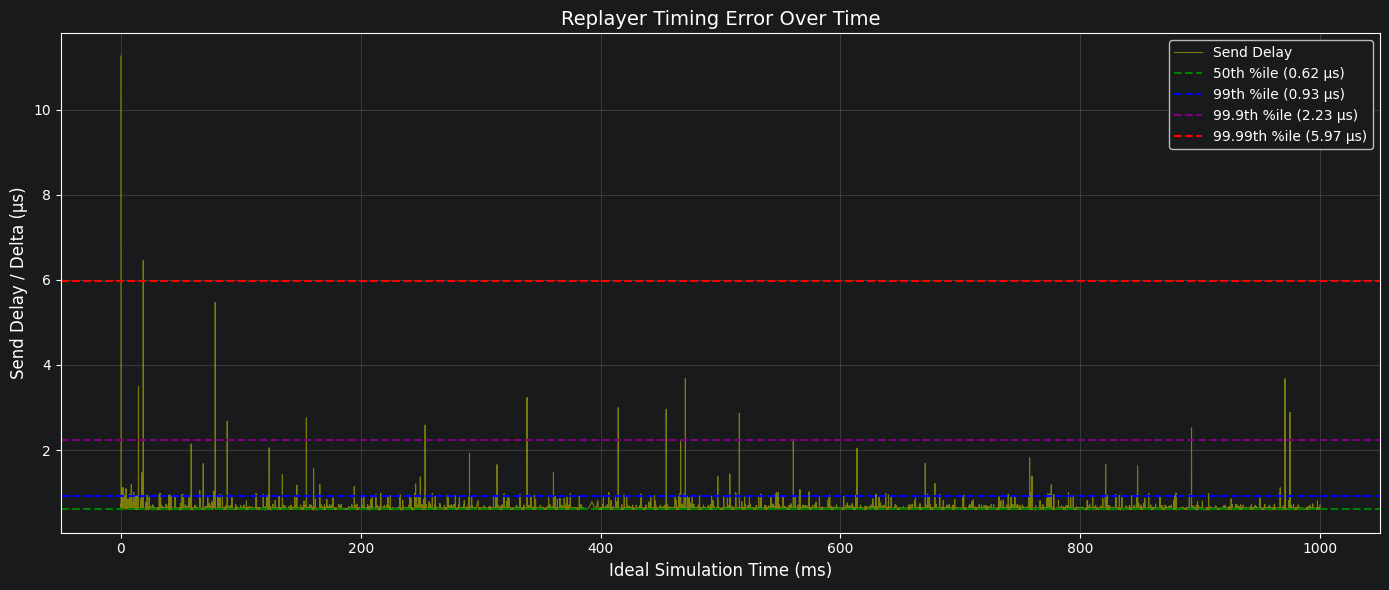

In [108]:
# Calculate percentiles
p50 = np.percentile(delta_us, 50)
p99 = np.percentile(delta_us, 99)
p99_9 = np.percentile(delta_us, 99.9)
p99_99 = np.percentile(delta_us, 99.99)

plt.figure(figsize=(14, 6))

# Plot the main timeline data
plt.plot(time_axis_ms, delta_us, color='y', alpha=0.6, linewidth=0.8, label="Send Delay")

# Add percentile dashed lines with distinct colors
plt.axhline(p50, color='green', linestyle='--', linewidth=1.5, label=f'50th %ile ({p50:.2f} µs)')
plt.axhline(p99, color='blue', linestyle='--', linewidth=1.5, label=f'99th %ile ({p99:.2f} µs)')
plt.axhline(p99_9, color='purple', linestyle='--', linewidth=1.5, label=f'99.9th %ile ({p99_9:.2f} µs)')
plt.axhline(p99_99, color='red', linestyle='--', linewidth=1.5, label=f'99.99th %ile ({p99_99:.2f} µs)')

# Formatting
plt.title("Replayer Timing Error Over Time", fontsize=14)
plt.xlabel("Ideal Simulation Time (ms)", fontsize=12)
plt.ylabel("Send Delay / Delta (µs)", fontsize=12)
plt.grid(True, alpha=0.3)

# Place the legend in the upper right (or 'best' to let matplotlib decide)
plt.legend(loc='best', framealpha=0.9)

plt.tight_layout()
plt.show()